# Milestone 1 – CIE: Data Transformation, Null Value Handling, Insight Generation and Visualization
**Dataset:** Online Sales Data (`sales_data.csv`)  
**Tools:** Python, Pandas, Matplotlib, Seaborn

## 1. Dataset Selection and Reading

In [6]:
%pip install seaborn


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("C:\\Users\\HP\\Downloads\\file\\sales_data.csv")
df.head()

,Order_ID,Customer_ID,Order_Date,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount,Customer_Age,Payment_Mode,Rating
0,ORD10001,CUST6128,2024-03-06,South,Electronics,Headphones,NaN,2471.90,5.0,18.0,Net Banking,5.0
1,ORD10002,CUST1277,2024-11-16,East,Books,Textbook,3.0,908.13,0.0,22.0,Debit Card,4.0
2,ORD10003,CUST5200,2024-11-12,South,Electronics,Smart Watch,4.0,5423.63,0.0,47.0,Credit Card,3.7
3,ORD10004,CUST2124,2025-09-19,West,Clothing,T-Shirt,2.0,632.55,5.0,NaN,UPI,4.9
4,ORD10005,CUST7249,2024-05-27,South,Clothing,Jeans,1.0,1966.15,5.0,18.0,UPI,4.1


## 2. Data Understanding

In [8]:
# number of rows and columns
df.shape

(3462, 12)

In [9]:
# column names
df.columns

Index(['Order_ID', 'Customer_ID', 'Order_Date', 'Region', 'Product_Category',
       'Product_Name', 'Quantity', 'Unit_Price', 'Discount', 'Customer_Age',
       'Payment_Mode', 'Rating'],
      dtype='str')

In [10]:
# data types and non-null count of every column
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3462 entries, 0 to 3461
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Order_ID          3462 non-null   str    
 1   Customer_ID       3462 non-null   str    
 2   Order_Date        3462 non-null   str    
 3   Region            3462 non-null   str    
 4   Product_Category  3462 non-null   str    
 5   Product_Name      3462 non-null   str    
 6   Quantity          3324 non-null   float64
 7   Unit_Price        3289 non-null   float64
 8   Discount          3255 non-null   float64
 9   Customer_Age      3220 non-null   float64
 10  Payment_Mode      3462 non-null   str    
 11  Rating            3186 non-null   float64
dtypes: float64(5), str(7)
memory usage: 324.7 KB


In [11]:
# statistical summary of numerical columns
df.describe()

,Quantity,Unit_Price,Discount,Customer_Age,Rating
count,3324.000000,3289.000000,3255.000000,3220.000000,3186.000000
mean,3.037004,5441.414518,7.150538,32.189441,3.983365
std,1.416175,11746.831918,6.822138,8.677767,0.656994
min,1.000000,225.290000,0.000000,18.000000,1.400000
25%,2.000000,698.490000,0.000000,26.000000,3.525000
50%,3.000000,2325.190000,5.000000,32.000000,4.000000
75%,4.000000,3350.750000,10.000000,38.000000,4.500000
max,5.000000,60431.410000,20.000000,63.000000,5.000000


In [12]:
# unique values in important categorical columns
print(df['Region'].unique())
print(df['Product_Category'].unique())
print(df['Payment_Mode'].unique())

<StringArray>
['South', 'East', 'West', 'North', 'Central']
Length: 5, dtype: str
<StringArray>
['Electronics', 'Books', 'Clothing', 'Home & Kitchen', 'Sports']
Length: 5, dtype: str
<StringArray>
['Net Banking', 'Debit Card', 'Credit Card', 'UPI', 'Cash on Delivery']
Length: 5, dtype: str


## 3. Data Transformation

In [13]:
# 3.1 Change data type: Order_Date is object (string), convert to datetime
df['Order_Date'] = pd.to_datetime(df['Order_Date'])
df.dtypes

Order_ID                       str
Customer_ID                    str
Order_Date          datetime64[us]
Region                         str
Product_Category               str
Product_Name                   str
Quantity                   float64
Unit_Price                 float64
Discount                   float64
Customer_Age               float64
Payment_Mode                   str
Rating                     float64
dtype: object

In [14]:
# 3.2 Drop unnecessary columns (IDs are not useful for analysis)
df = df.drop(['Order_ID', 'Customer_ID'], axis=1)
df.columns

Index(['Order_Date', 'Region', 'Product_Category', 'Product_Name', 'Quantity',
       'Unit_Price', 'Discount', 'Customer_Age', 'Payment_Mode', 'Rating'],
      dtype='str')

In [15]:
# 3.3 Add new columns from the date
df['Year'] = df['Order_Date'].dt.year
df['Month'] = df['Order_Date'].dt.month
df['Month_Name'] = df['Order_Date'].dt.month_name()
df[['Order_Date', 'Year', 'Month', 'Month_Name']].head()

,Order_Date,Year,Month,Month_Name
0,2024-03-06,2024,3,March
1,2024-11-16,2024,11,November
2,2024-11-12,2024,11,November
3,2025-09-19,2025,9,September
4,2024-05-27,2024,5,May


## 4. Handling Null Values

In [16]:
# 4.1 Identify null values
df.isnull().sum()

Order_Date            0
Region                0
Product_Category      0
Product_Name          0
Quantity            138
Unit_Price          173
Discount            207
Customer_Age        242
Payment_Mode          0
Rating              276
Year                  0
Month                 0
Month_Name            0
dtype: int64

In [17]:
# percentage of null values in each column
(df.isnull().sum() / len(df)) * 100

Order_Date          0.000000
Region              0.000000
Product_Category    0.000000
Product_Name        0.000000
Quantity            3.986135
Unit_Price          4.997111
Discount            5.979203
Customer_Age        6.990179
Payment_Mode        0.000000
Rating              7.972270
Year                0.000000
Month               0.000000
Month_Name          0.000000
dtype: float64

In [18]:
# 4.2 Mean imputation for numerical columns
cols = ['Quantity', 'Unit_Price', 'Discount', 'Customer_Age', 'Rating']

for col in cols:
    df[col] = df[col].fillna(df[col].mean())

# Quantity and Customer_Age are whole numbers, so round them
df['Quantity'] = df['Quantity'].round().astype(int)
df['Customer_Age'] = df['Customer_Age'].round().astype(int)

In [19]:
# 4.3 Check again - all should be 0
df.isnull().sum()

Order_Date          0
Region              0
Product_Category    0
Product_Name        0
Quantity            0
Unit_Price          0
Discount            0
Customer_Age        0
Payment_Mode        0
Rating              0
Year                0
Month               0
Month_Name          0
dtype: int64

In [20]:
# 3.4 Add Revenue column (after null handling so that no value is missing)
df['Revenue'] = df['Quantity'] * df['Unit_Price'] * (1 - df['Discount'] / 100)
df['Revenue'] = df['Revenue'].round(2)
df.head()

,Order_Date,Region,Product_Category,Product_Name,Quantity,Unit_Price,Discount,Customer_Age,Payment_Mode,Rating,Year,Month,Month_Name,Revenue
0,2024-03-06,South,Electronics,Headphones,3,2471.90,5.0,18,Net Banking,5.0,2024,3,March,7044.92
1,2024-11-16,East,Books,Textbook,3,908.13,0.0,22,Debit Card,4.0,2024,11,November,2724.39
2,2024-11-12,South,Electronics,Smart Watch,4,5423.63,0.0,47,Credit Card,3.7,2024,11,November,21694.52
3,2025-09-19,West,Clothing,T-Shirt,2,632.55,5.0,32,UPI,4.9,2025,9,September,1201.84
4,2024-05-27,South,Clothing,Jeans,1,1966.15,5.0,18,UPI,4.1,2024,5,May,1867.84


## 5. Insight Generation

In [21]:
# Insight 1: Total revenue, total orders and average order value
print('Total Revenue       :', round(df['Revenue'].sum(), 2))
print('Total Orders        :', len(df))
print('Average Order Value :', round(df['Revenue'].mean(), 2))

Total Revenue       : 53871762.05
Total Orders        : 3462
Average Order Value : 15560.88


In [22]:
# Insight 2: Region-wise revenue
region_revenue = df.groupby('Region')['Revenue'].sum().sort_values(ascending=False)
region_revenue

Region
South      16348810.16
West       14620190.47
North      10139388.96
East        8473858.27
Central     4289514.19
Name: Revenue, dtype: float64

In [23]:
# Insight 3: Category-wise revenue
category_revenue = df.groupby('Product_Category')['Revenue'].sum().sort_values(ascending=False)
category_revenue

Product_Category
Electronics       38461649.19
Home & Kitchen     6371742.22
Clothing           4280614.91
Sports             3401219.68
Books              1356536.05
Name: Revenue, dtype: float64

In [24]:
# Insight 4: Monthly sales trend (year + month)
monthly_revenue = df.groupby(['Year', 'Month'])['Revenue'].sum().reset_index()
monthly_revenue['Period'] = monthly_revenue['Year'].astype(str) + '-' + monthly_revenue['Month'].astype(str).str.zfill(2)
monthly_revenue.head()

,Year,Month,Revenue,Period
0,2024,1,1559891.16,2024-01
1,2024,2,1952603.09,2024-02
2,2024,3,2002542.33,2024-03
3,2024,4,1396610.47,2024-04
4,2024,5,2879563.27,2024-05


In [25]:
# Insight 5: Year-wise revenue
df.groupby('Year')['Revenue'].sum()

Year
2024    27932947.96
2025    25938814.09
Name: Revenue, dtype: float64

In [26]:
# Insight 6: Top 5 products by revenue
top_products = df.groupby('Product_Name')['Revenue'].sum().sort_values(ascending=False).head(5)
top_products

Product_Name
Laptop           25426745.02
Smartphone        8761091.67
Smart Watch       3072586.70
Air Fryer         2494730.89
Mixer Grinder     1900611.87
Name: Revenue, dtype: float64

In [27]:
# Insight 7: Payment mode usage
payment_counts = df['Payment_Mode'].value_counts()
payment_counts

Payment_Mode
UPI                 1292
Credit Card          777
Debit Card           570
Cash on Delivery     529
Net Banking          294
Name: count, dtype: int64

In [31]:
# Insight 8: Average rating by category
df.groupby('Product_Category')['Rating'].mean().round(2).sort_values(ascending=False)

Product_Category
Home & Kitchen    4.00
Books             3.99
Electronics       3.99
Clothing          3.97
Sports            3.97
Name: Rating, dtype: float64

In [32]:
# Insight 9: Best and worst month
best = monthly_revenue.loc[monthly_revenue['Revenue'].idxmax()]
worst = monthly_revenue.loc[monthly_revenue['Revenue'].idxmin()]
print('Best month  :', best['Period'], '->', round(best['Revenue'], 2))
print('Worst month :', worst['Period'], '->', round(worst['Revenue'], 2))

Best month  : 2025-11 -> 3643007.87
Worst month : 2025-02 -> 1244983.9


## 6. Data Visualization

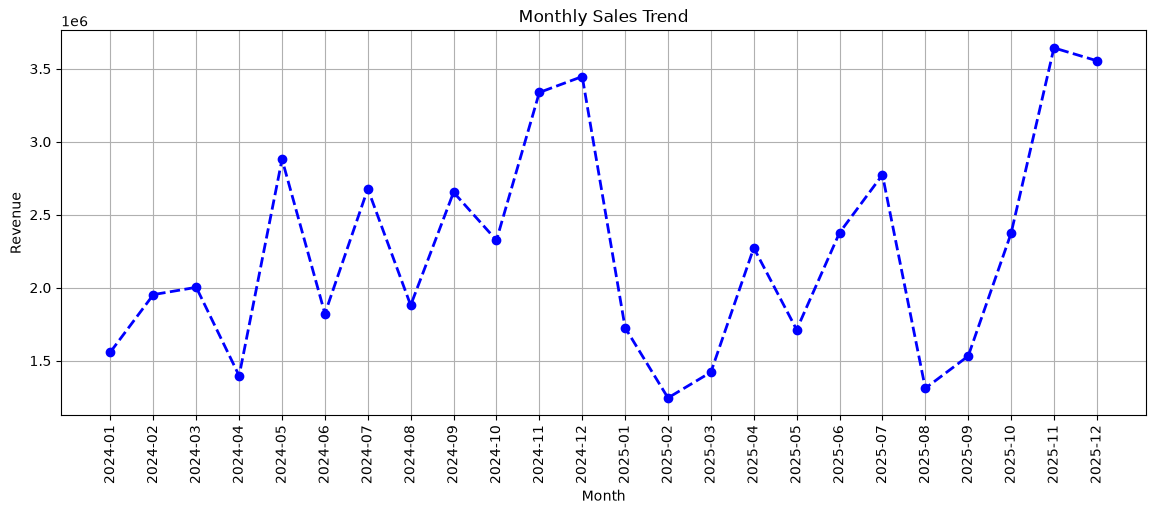

In [33]:
# Chart 1: Monthly sales trend (line chart)
plt.figure(figsize=(14, 5))
plt.plot(monthly_revenue['Period'], monthly_revenue['Revenue'], color='blue', linestyle='--', marker='o', linewidth=2, markersize=6)
plt.xlabel('Month')
plt.ylabel('Revenue')
plt.title('Monthly Sales Trend')
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

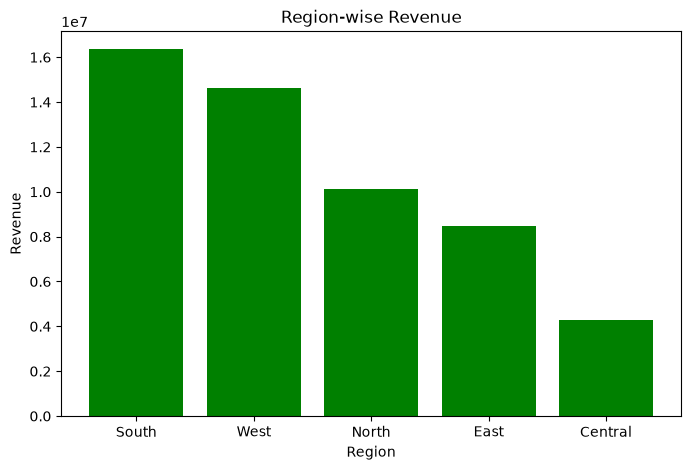

In [34]:
# Chart 2: Region-wise revenue (bar chart)
plt.figure(figsize=(8, 5))
plt.bar(region_revenue.index, region_revenue.values, color='green')
plt.xlabel('Region')
plt.ylabel('Revenue')
plt.title('Region-wise Revenue')
plt.show()

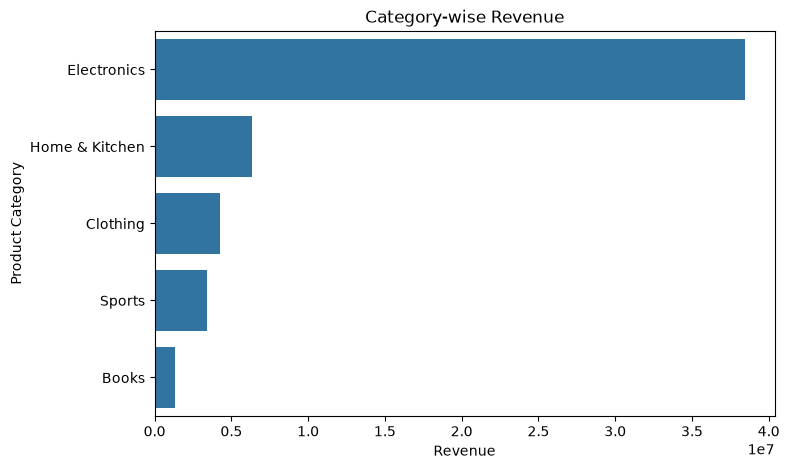

In [35]:
# Chart 3: Category-wise revenue (horizontal bar chart)
plt.figure(figsize=(8, 5))
sns.barplot(x=category_revenue.values, y=category_revenue.index)
plt.xlabel('Revenue')
plt.ylabel('Product Category')
plt.title('Category-wise Revenue')
plt.show()

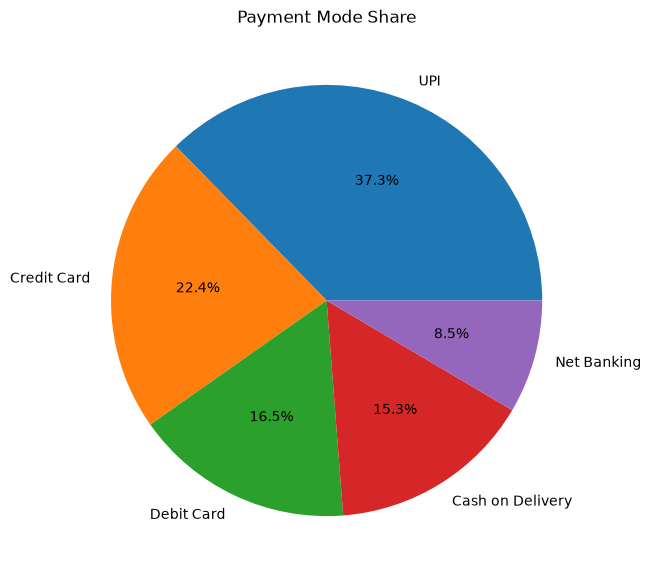

In [36]:
# Chart 4: Payment mode share (pie chart)
plt.figure(figsize=(7, 7))
plt.pie(payment_counts.values, labels=payment_counts.index, autopct='%1.1f%%')
plt.title('Payment Mode Share')
plt.show()

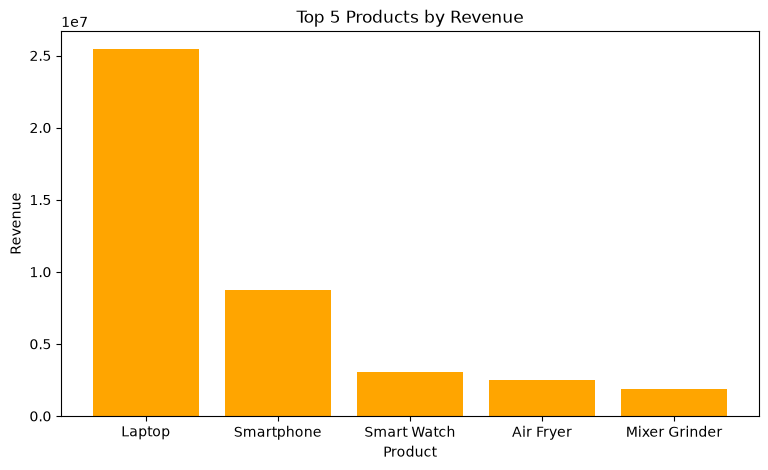

In [37]:
# Chart 5: Top 5 products (bar chart)
plt.figure(figsize=(9, 5))
plt.bar(top_products.index, top_products.values, color='orange')
plt.xlabel('Product')
plt.ylabel('Revenue')
plt.title('Top 5 Products by Revenue')
plt.show()

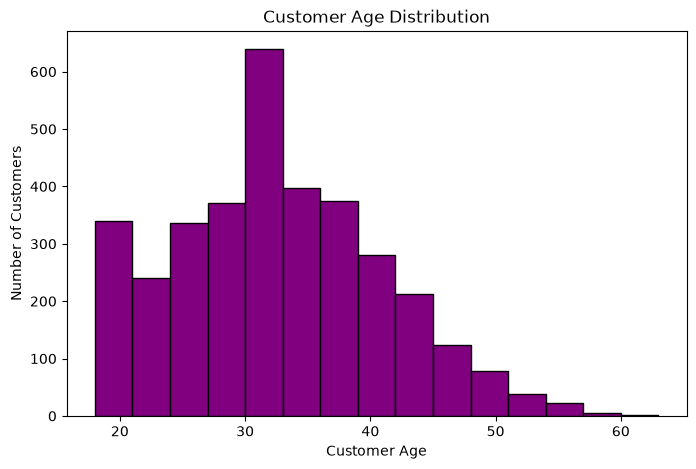

In [38]:
# Chart 6: Distribution of customer age (histogram)
plt.figure(figsize=(8, 5))
plt.hist(df['Customer_Age'], bins=15, color='purple', edgecolor='black')
plt.xlabel('Customer Age')
plt.ylabel('Number of Customers')
plt.title('Customer Age Distribution')
plt.show()

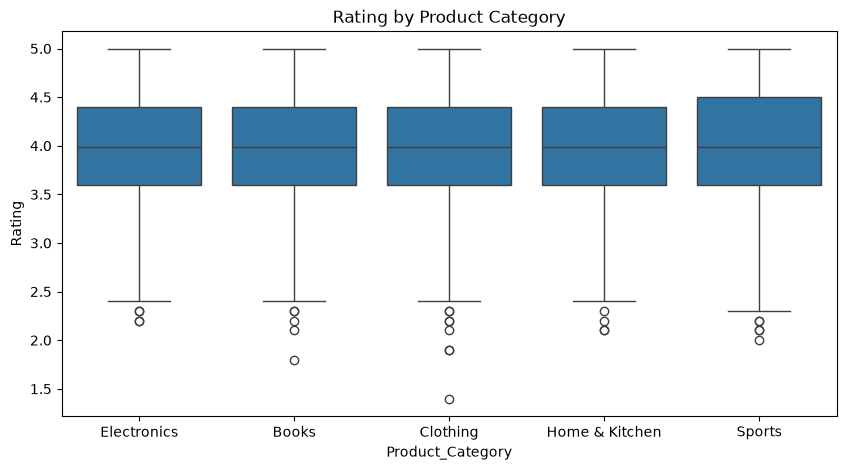

In [39]:
# Chart 7: Rating by category (box plot)
plt.figure(figsize=(10, 5))
sns.boxplot(x='Product_Category', y='Rating', data=df)
plt.title('Rating by Product Category')
plt.show()

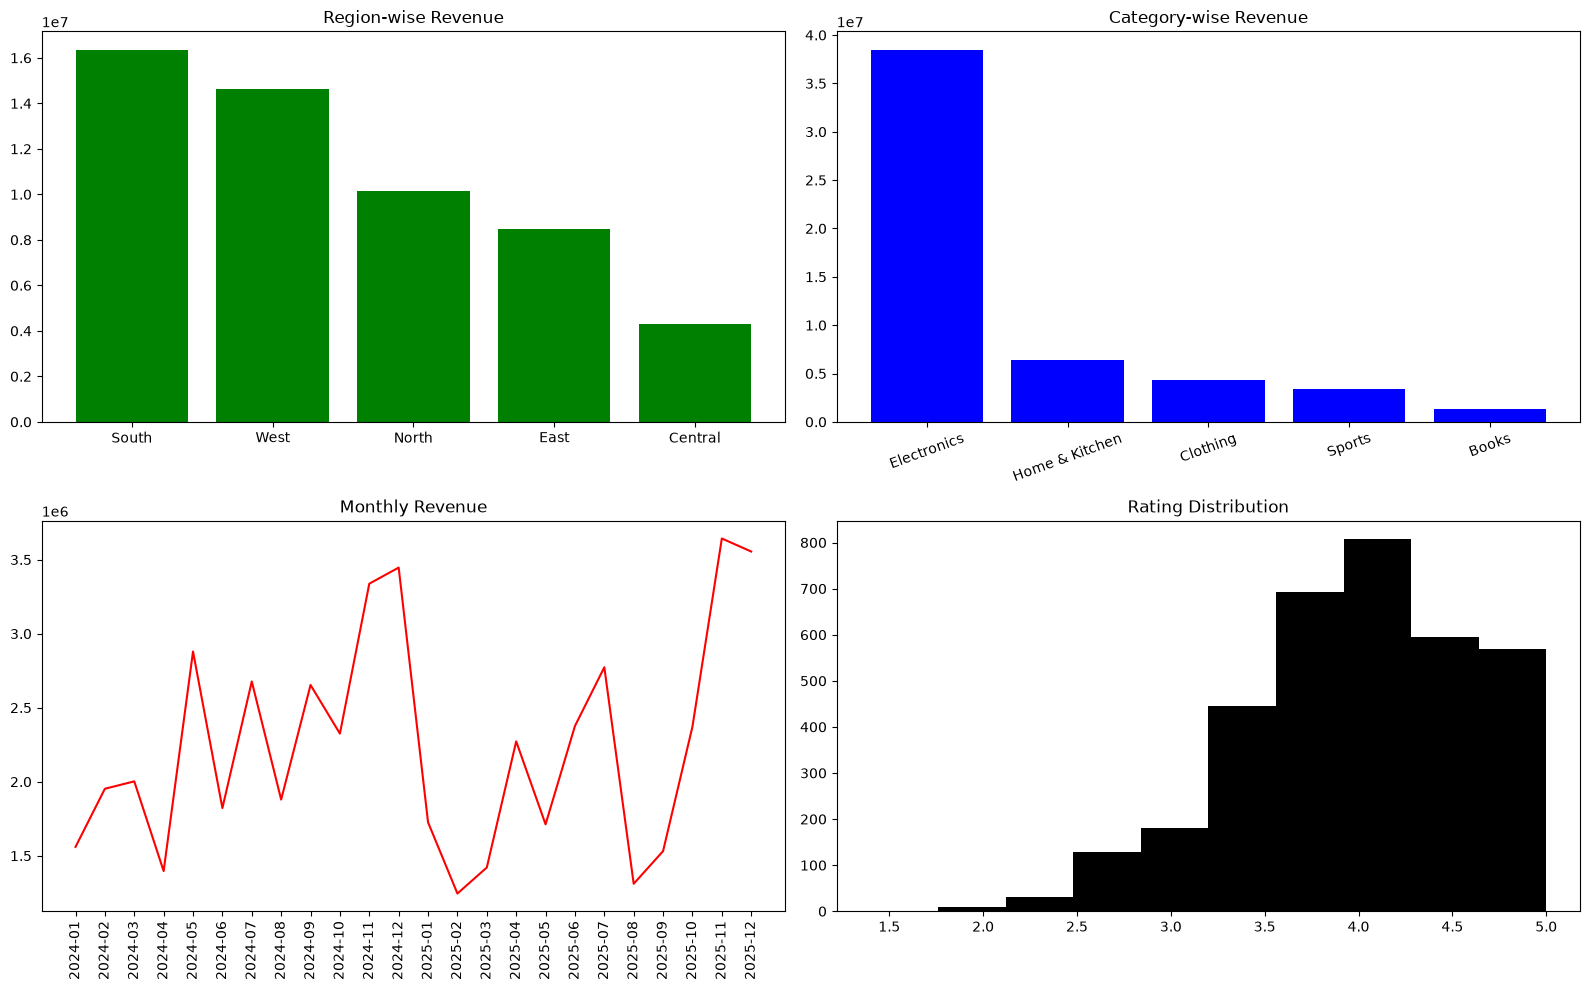

In [40]:
# Chart 8: Dashboard using subplots (same idea as taught in class)
plt.figure(figsize=(16, 10))

plt.subplot(2, 2, 1)
plt.bar(region_revenue.index, region_revenue.values, color='green')
plt.title('Region-wise Revenue')

plt.subplot(2, 2, 2)
plt.bar(category_revenue.index, category_revenue.values, color='blue')
plt.xticks(rotation=20)
plt.title('Category-wise Revenue')

plt.subplot(2, 2, 3)
plt.plot(monthly_revenue['Period'], monthly_revenue['Revenue'], color='red')
plt.xticks(rotation=90)
plt.title('Monthly Revenue')

plt.subplot(2, 2, 4)
plt.hist(df['Rating'], bins=10, color='black')
plt.title('Rating Distribution')

plt.tight_layout()
plt.show()

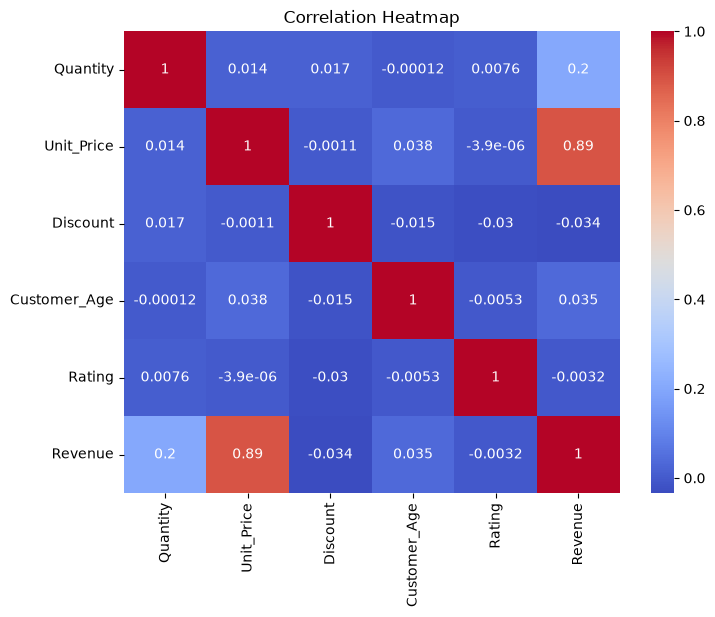

In [41]:
# Chart 9: Correlation heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(df[['Quantity', 'Unit_Price', 'Discount', 'Customer_Age', 'Rating', 'Revenue']].corr(), annot=True, cmap='coolwarm')
plt.title('Correlation Heatmap')
plt.show()